> **Revisão documental — 20/10/2026:** Saídas históricas preservadas. C6 conserva apenas a contagem antiga, sem o intervalo de datas hoje impresso. A figura de C46 também foi preservada após a revisão dos rótulos; ainda não foi revalidada. Execução integral desta revisão no Colab pendente.

# Prática de Clusterização - Online Retail

Autor: Wellington Morais

Data do experimento: 14/04/2026

---

**Baseado no exemplo de Manish Kumar** (https://www.kaggle.com/hellbuoy/online-retail-kmeans-hierarchical-clustering)

Este exercício carrega `online_retail_II.xlsx` da fonte Kaggle indicada no código.
Na execução histórica preservada, a carga analisada continha 525.461 registros,
de 01/12/2009 a 09/12/2010, antes da limpeza. O conjunto completo Online Retail II
é descrito pela [UCI](https://archive.ics.uci.edu/dataset/502/online+retail+ii) como
abrangendo dezembro de 2009 a dezembro de 2011. Em 2026-10-19, a versão 1 do
arquivo Kaggle foi conferida: contém as abas `Year 2009-2010` e `Year 2010-2011`.
Este exercício seleciona explicitamente `Year 2009-2010`, com 525.461 registros
e o período histórico indicado acima. O período efetivo e a contagem são
exibidos abaixo em cada execução.

As saídas e figuras salvas são históricas e foram preservadas. Elas ainda não
refletem as correções de código e apresentação, que exigem nova execução.

As etapas são amplamente divididas em:
* Etapa 1: Leitura e compreensão dos dados
* Etapa 2: limpeza de dados
* Etapa 3: preparação de dados
* Etapa 4: construção de modelo
* Etapa 5: Análise Final

Boa atividade!

In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
%matplotlib inline

In [24]:
# Dependências para carregar o arquivo Excel pelo adaptador Pandas.
%pip install -q "kagglehub[pandas-datasets]" openpyxl
import pandas as pd
import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "online_retail_II.xlsx"
# A primeira aba usada na prática foi identificada em 2026-10-19.
df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "lakshmi25npathi/online-retail-dataset/versions/1",
    file_path,
    pandas_kwargs={"sheet_name": "Year 2009-2010"},
)

required_columns = {"Invoice", "StockCode", "Description", "Quantity", "InvoiceDate", "Price", "Customer ID", "Country"}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Colunas ausentes no Online Retail: {sorted(missing_columns)}")
if df.empty or df["InvoiceDate"].isna().any():
    raise ValueError("Online Retail sem registros ou com datas ausentes")
# Valida a conversão; a transformação do DataFrame permanece na etapa própria.
pd.to_datetime(df["InvoiceDate"], errors="raise")

print("Primeiros 5 registros:", df.head())

Using Colab cache for faster access to the 'online-retail-dataset' dataset.
First 5 records:   Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

          InvoiceDate  Price  Customer ID         Country  
0 2009-12-01 07:45:00   6.95      13085.0  United Kingdom  
1 2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
2 2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
3 2009-12-01 07:45:00   2.10      13085.0  United Kingdom  
4 2009-12-01 07:45:00   1.25      13085.0  United Kingdom  


# Etapa 1: Leitura e compreensão dos dados

In [25]:
# Em vez de ler o arquivo novamente, usamos o DataFrame 'df' que já foi carregado com sucesso anteriormente
retail = df.copy()
retail.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [26]:
print("quantidade de registros: %d" % retail.shape[0])
# Diagnóstico da carga efetiva antes da limpeza, sem alterar o DataFrame.
print("InvoiceDate mínimo:", retail["InvoiceDate"].min())
print("InvoiceDate máximo:", retail["InvoiceDate"].max())

quantidade de registros: 525461


In [27]:
retail.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[ns]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 32.1+ MB


In [28]:
retail.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,525461.000000,525461,525461.000000,417534.000000
mean,10.337667,2010-06-28 11:37:36.845017856,4.688834,15360.645478
min,-9600.000000,2009-12-01 07:45:00,-53594.360000,12346.000000
25%,1.000000,2010-03-21 12:20:00,1.250000,13983.000000
50%,3.000000,2010-07-06 09:51:00,2.100000,15311.000000
75%,10.000000,2010-10-15 12:45:00,4.210000,16799.000000
max,19152.000000,2010-12-09 20:01:00,25111.090000,18287.000000
std,107.424110,NaN,146.126914,1680.811316


# Etapa 2: Data Cleaning

Nesta etapa identicaremos os registros nulos ou que possuem alguma inconsistência

## Identicando e excluindo os regitros com atributos nulos

In [29]:
df_null = round(100*(retail.isnull().sum())/len(retail), 2)
df_null

,0
Invoice,0.00
StockCode,0.00
Description,0.56
Quantity,0.00
InvoiceDate,0.00
Price,0.00
Customer ID,20.54
Country,0.00


In [30]:
retail = retail.dropna()

In [31]:
print("quantidade de registros: %d" % retail.shape[0])

quantidade de registros: 417534


# Etapa 3: Preparação dos dados

Nesta etapa realizaremos a conversão de tipos, construção dos atributos, exclusão de amostras
expurias e transformação de escala dos dados

## Conversão do tipo de dados do atributo Price e do InvoiceDate

1. Conversão do tipo do atributo InvoiceDate para datetime
2. Conversão do tipo do atributo Price para ponto flutuante
3. Conversão do tipo do atributo Customer ID para texto

In [33]:
# 1. Convertendo o campo Customer ID para string (ajustado o nome da coluna)
retail['Customer ID'] = retail['Customer ID'].astype(str)

# 2. O campo InvoiceDate já é datetime, mas garantimos a conversão se necessário
retail['InvoiceDate'] = pd.to_datetime(retail['InvoiceDate'])

# 3. No seu dataset a coluna se chama 'Price'.
# Como ela já é numérica (float64), não precisamos substituir vírgula por ponto.
retail['Price'] = pd.to_numeric(retail['Price'])

retail.info()

<class 'pandas.core.frame.DataFrame'>
Index: 417534 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      417534 non-null  object        
 1   StockCode    417534 non-null  object        
 2   Description  417534 non-null  object        
 3   Quantity     417534 non-null  int64         
 4   InvoiceDate  417534 non-null  datetime64[ns]
 5   Price        417534 non-null  float64       
 6   Customer ID  417534 non-null  object        
 7   Country      417534 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(5)
memory usage: 28.7+ MB


## Criando campos para o agrupamento (Feature Engeneering)

Para realizar o trabalho, nos ainda criaremos três campos. Esse processo é chamado feature
engineering. Os campos que criaremos nos ajudarão a compreender o comportamento dos
clientes. São eles:

1. R (Recencia): número de dias desde a última compra
2. F (Frequência): quantidade de linhas de fatura por cliente após a limpeza
   (contagem de valores não nulos em Invoice; não é a quantidade de compras distintas)
3. M (Faturamento): Faturamento total do cliente


### Criando o atributo Faturamento total do cliente

In [35]:
# criamos um novo campo com o total de cada compra
retail['Amount'] = retail['Quantity']*retail['Price']
# fazemos o agrupamento das compras por CustormerID
rfm_m = retail.groupby('Customer ID')['Amount'].sum()
rfm_m = rfm_m.reset_index()
rfm_m.head()

,Customer ID,Amount
0,12346.0,-64.68
1,12347.0,1323.32
2,12348.0,222.16
3,12349.0,2646.99
4,12351.0,300.93


### Criando a frequência como quantidade de linhas de fatura por cliente

O `count()` conta valores não nulos de `Invoice` após a limpeza. Uma mesma fatura
pode aparecer em várias linhas. Contar faturas distintas com `nunique()` mudaria
a definição do atributo e exigiria refazer o experimento; essa alteração não foi aplicada.


In [37]:
rfm_f = retail.groupby('Customer ID')['Invoice'].count()
rfm_f = rfm_f.reset_index()
rfm_f.columns = ['Customer ID', 'Frequency']
rfm_f.head()

,Customer ID,Frequency
0,12346.0,46
1,12347.0,71
2,12348.0,20
3,12349.0,107
4,12351.0,21


### Criando o atributo de Recência de Compras

In [38]:
# selecionamos a última compra de toda a base
max_date = max(retail['InvoiceDate'])
# Criamos um atributo que identifica o tempo em dias desde a compra mais recente da base
retail['Diff'] = max_date - retail['InvoiceDate']
retail.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Amount,Diff
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4,373 days 12:16:00
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0,373 days 12:16:00
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0,373 days 12:16:00
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8,373 days 12:16:00
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0,373 days 12:16:00


In [39]:
# pegamos a compra mais recente de cada cliente
rfm_p = retail.groupby('Customer ID')['Diff'].min()
rfm_p = rfm_p.reset_index()
rfm_p.head()


,Customer ID,Diff
0,12346.0,66 days 03:28:00
1,12347.0,2 days 05:04:00
2,12348.0,73 days 05:02:00
3,12349.0,42 days 11:38:00
4,12351.0,10 days 04:38:00


In [40]:
# como queremos somentes os dias...
rfm_p['Diff'] = rfm_p['Diff'].dt.days
rfm_p.head()

,Customer ID,Diff
0,12346.0,66
1,12347.0,2
2,12348.0,73
3,12349.0,42
4,12351.0,10


### Realizando a junção dos campos criados em uma nova base de dados

In [43]:
# utilizamos a função merge do pandas para realizar a mesclagem das bases através do atrib
dataset = pd.merge(rfm_m, rfm_f, on='Customer ID', how='inner')
dataset = pd.merge(dataset, rfm_p, on='Customer ID', how='inner')
dataset.columns = ['Customer ID', 'Amount', 'Frequency', 'Recency']
dataset.head()

,Customer ID,Amount,Frequency,Recency
0,12346.0,-64.68,46,66
1,12347.0,1323.32,71,2
2,12348.0,222.16,20,73
3,12349.0,2646.99,107,42
4,12351.0,300.93,21,10


## Identicando outliers

Para a realização do agrupamento é importante identicar se existem dados expurios que
podem dicultar o processo de agrupamento

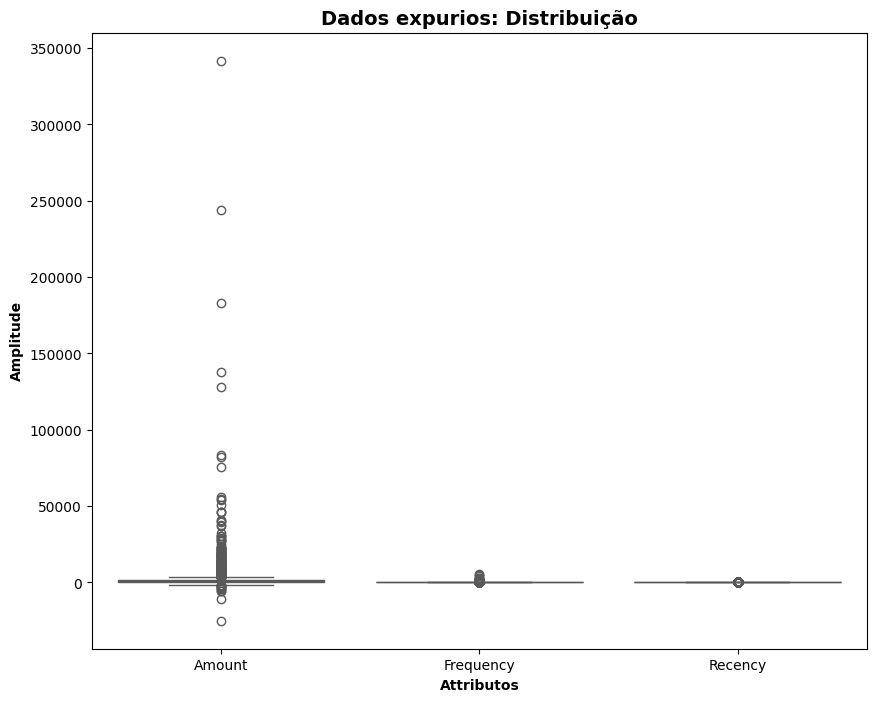

In [46]:
def print_oultiers_distribution(data, attributes):
    plt.rcParams['figure.figsize'] = [10,8]
    sns.boxplot(data = data[attributes], orient="v", palette="Set2", whis=1.5)
    plt.title("Dados expurios: Distribuição", fontsize = 14, fontweight = 'bold')
    plt.ylabel("Amplitude", fontweight = 'bold')
    plt.xlabel("Attributos", fontweight = 'bold')

print_oultiers_distribution(dataset, ['Amount','Frequency','Recency'])

### Removendo os dados expurios

Faremos a exclusão dos dados que podem atrapalhar a qualidade do agrupamento.

**Hora da estatística!**

Manteremos desta bases os dados que estão entre os quantis 5% e 95%.

In [47]:
import pandas as pd

# Filtrando outliers para 'Amount'
Q1 = dataset.Amount.quantile(0.05)
Q3 = dataset.Amount.quantile(0.95)
dataset = dataset[(dataset.Amount >= Q1) & (dataset.Amount <= Q3)]

# Filtrando outliers para 'Frequency'
Q1 = dataset.Frequency.quantile(0.05)
Q3 = dataset.Frequency.quantile(0.95)
dataset = dataset[(dataset.Frequency >= Q1) & (dataset.Frequency <= Q3)]

# Filtrando outliers para 'Recency'
Q1 = dataset.Recency.quantile(0.05)
Q3 = dataset.Recency.quantile(0.95)
dataset = dataset[(dataset.Recency >= Q1) & (dataset.Recency <= Q3)]

print("Novo formato do dataset após remoção de outliers:", dataset.shape)
display(dataset.head())

Novo formato do dataset após remoção de outliers: (3229, 4)


,Customer ID,Amount,Frequency,Recency
1,12347.0,1323.32,71,2
2,12348.0,222.16,20,73
3,12349.0,2646.99,107,42
4,12351.0,300.93,21,10
5,12352.0,343.80,18,10


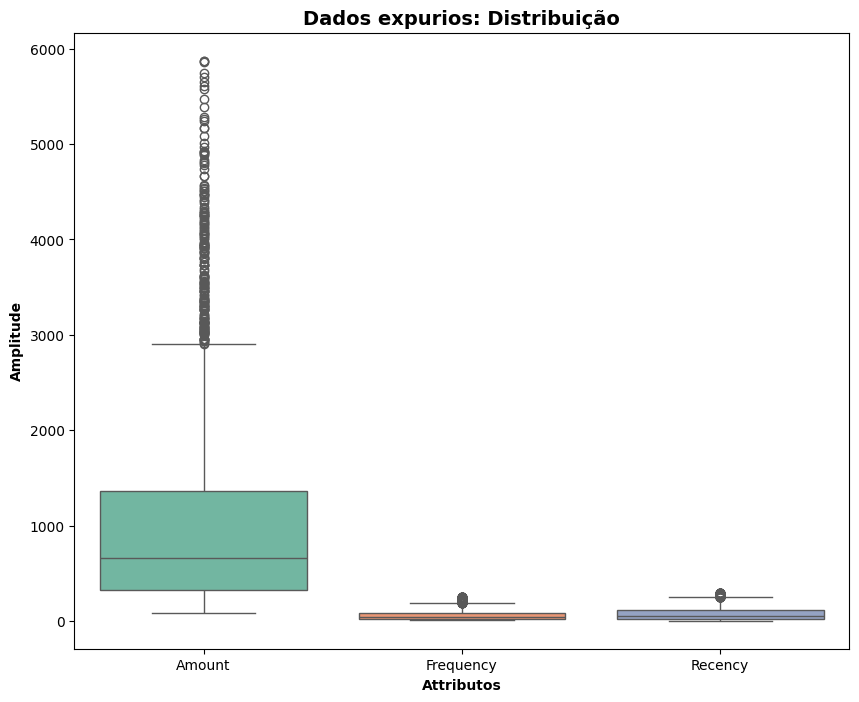

In [48]:
# Visualizando a nova distribuição sem os principais outliers
print_oultiers_distribution(dataset, ['Amount','Frequency','Recency'])

## Escalonamento dos Dados (Standardization)

Padronizamos os atributos RFM com `StandardScaler` para reduzir diferenças de
escala. Nos atributos não constantes, os dados usados no ajuste ficam com média
próxima de zero e variância unitária; atributos constantes ficam com variância
zero. Isso não garante igual importância ou influência no agrupamento: as
distribuições e correlações também afetam a geometria das distâncias.

In [49]:
from sklearn.preprocessing import StandardScaler

# Selecionando apenas as colunas numéricas para o escalonamento
rfm_df = dataset[['Amount', 'Frequency', 'Recency']]

# Inicializando o scaler
scaler = StandardScaler()

# Ajustando e transformando os dados
rfm_df_scaled = scaler.fit_transform(rfm_df)

# Convertendo de volta para um DataFrame para facilitar a visualização
rfm_df_scaled = pd.DataFrame(rfm_df_scaled)
rfm_df_scaled.columns = ['Amount', 'Frequency', 'Recency']
rfm_df_scaled.head()

,Amount,Frequency,Recency
0,0.301301,0.122121,-1.012261
1,-0.806750,-0.779990,-0.085142
2,1.633254,0.758905,-0.489941
3,-0.727487,-0.762301,-0.907797
4,-0.684349,-0.815367,-0.907797


## Rescalando os Atributos

Para evitar que a amplitude dos atributos possa prejudicar o agrupamento, faremos a mudança
da escala utilizando o StandardScaler


In [50]:
dados = dataset[['Amount', 'Frequency', 'Recency']]

In [51]:
from sklearn.preprocessing import StandardScaler

In [52]:
# Criamos o Scaler
scaler = StandardScaler()
# fit_transform
dados_rescalados = scaler.fit_transform(dados)

In [53]:
dataset_scaled = pd.DataFrame(dados_rescalados)
dataset_scaled.columns = ['Amount', 'Frequency', 'Recency']
dataset_scaled.head()


,Amount,Frequency,Recency
0,0.301301,0.122121,-1.012261
1,-0.806750,-0.779990,-0.085142
2,1.633254,0.758905,-0.489941
3,-0.727487,-0.762301,-0.907797
4,-0.684349,-0.815367,-0.907797


# Etapa 4: Construindo o modelo

## K-means

O clustering K-means é um dos algoritmos de aprendizado de máquina não supervisionado
mais simples e populares.

O algoritmo funciona da seguinte maneira:

1. Primeiro, inicializamos k pontos, chamados meios, aleatoriamente.
2. Categorizamos cada item para sua média mais próxima e atualizamos as coordenadas da
média, que são as médias dos itens categorizados nessa média até agora.
3. Repetimos o processo para um determinado número de iterações e, ao nal, temos
nossos clusters.

Avaliaremos, também a qualidade dos clusters obtidos com o coeciente de silhoueta

In [54]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [56]:
ssd = []
sil = []
range_n_clusters = [2, 3, 4, 5, 6, 7, 8]

for num_clusters in range_n_clusters:
    # Inicializa e treina o KMeans
    kmeans = KMeans(n_clusters=num_clusters, max_iter=50, random_state=42, n_init=10)
    kmeans.fit(dataset_scaled)

    # Calcula o SSD (Soma dos quadrados das distâncias)
    ssd.append(kmeans.inertia_)

    # Calcula o silhouette score
    silhouette_avg = silhouette_score(dataset_scaled, kmeans.labels_)
    sil.append(silhouette_avg)

print('SSD:', ssd)
print('Silhouette Scores:', sil)

SSD: [5595.662724812224, 3410.6492460530476, 2722.8523697207506, 2260.7746992705047, 1991.0926097955255, 1841.3356326246721, 1604.3204453812182]
Silhouette Scores: [np.float64(0.44277130863245306), np.float64(0.4580548934168804), np.float64(0.40393890549288464), np.float64(0.397830241439355), np.float64(0.36677465966897005), np.float64(0.35666460497219243), np.float64(0.33891889260087277)]


/tmp/ipykernel_698/3469215403.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(range_n_clusters)


[Text(-1.0, 0, '2'),
 Text(0.0, 0, '3'),
 Text(1.0, 0, '4'),
 Text(2.0, 0, '5'),
 Text(3.0, 0, '6'),
 Text(4.0, 0, '7'),
 Text(5.0, 0, '8'),
 Text(6.0, 0, ''),
 Text(7.0, 0, '')]

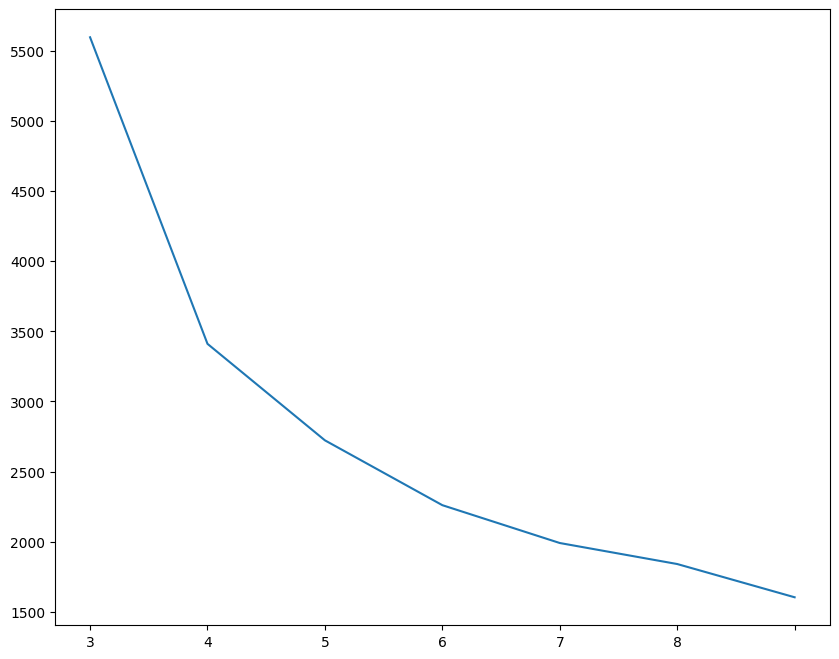

In [57]:
# Cada SSD é associado ao número de clusters que o produziu.
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(range_n_clusters, ssd, marker="o")
ax.set_xticks(range_n_clusters)
ax.set_xlabel("Número de clusters (k)")
ax.set_ylabel("SSD (inércia)")
ax.set_title("K-Means: inércia por número de clusters")
fig.tight_layout()
plt.show()

/tmp/ipykernel_698/445147792.py:3: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(range_n_clusters)


[Text(-1.0, 0, '2'),
 Text(0.0, 0, '3'),
 Text(1.0, 0, '4'),
 Text(2.0, 0, '5'),
 Text(3.0, 0, '6'),
 Text(4.0, 0, '7'),
 Text(5.0, 0, '8'),
 Text(6.0, 0, ''),
 Text(7.0, 0, '')]

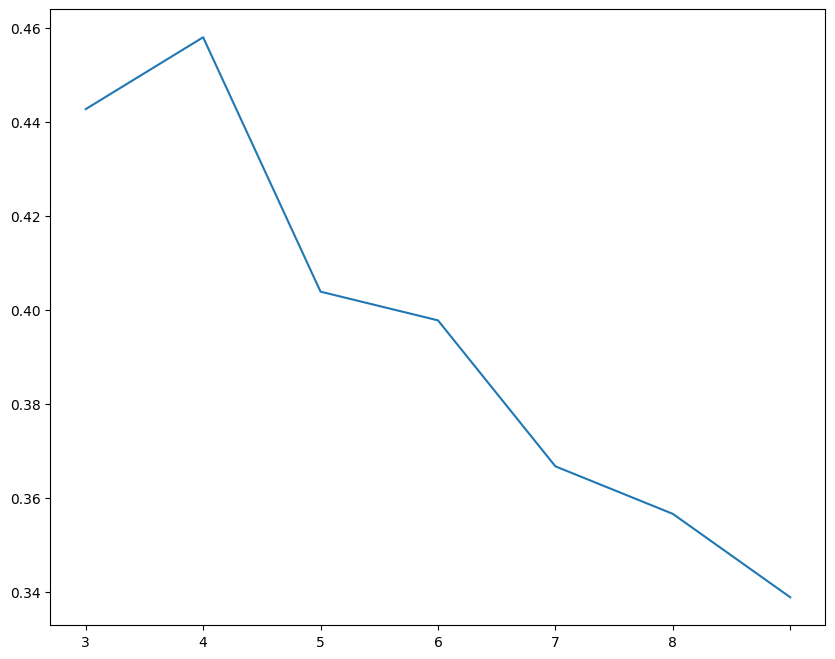

In [58]:
# Cada score de silhueta é associado ao k correspondente, em figura própria.
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(range_n_clusters, sil, marker="o")
ax.set_xticks(range_n_clusters)
ax.set_xlabel("Número de clusters (k)")
ax.set_ylabel("Silhueta média")
ax.set_title("K-Means: silhueta por número de clusters")
fig.tight_layout()
plt.show()

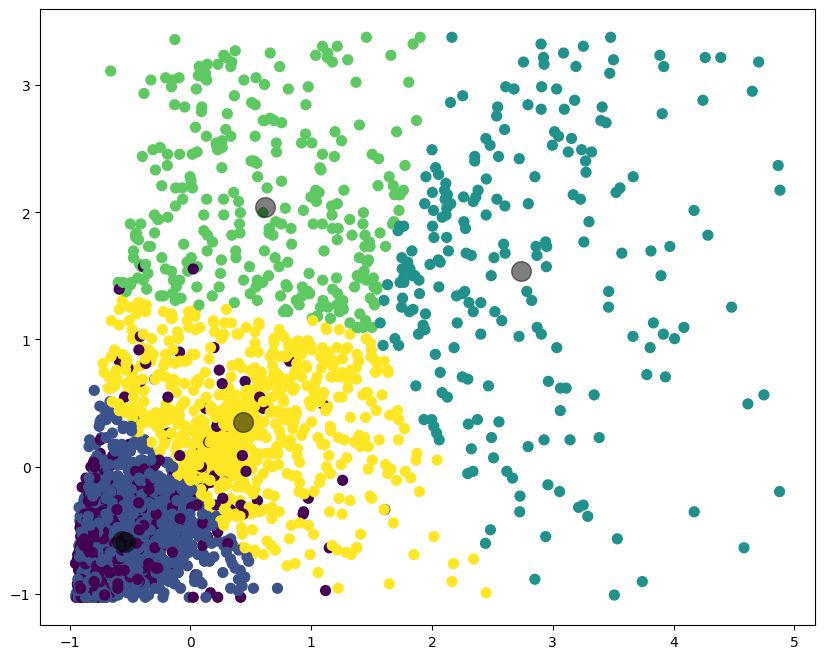

In [59]:
# O exemplo mantém cinco clusters; a justificativa dessa escolha não está registrada.
# Na saída histórica, a maior silhueta entre k=2...8 ocorreu com k=3, não k=5.
kmeans = KMeans(n_clusters=5, n_init=10, random_state=42)
kmeans.fit(dataset_scaled)
y_kmeans = kmeans.predict(dataset_scaled)
centers = kmeans.cluster_centers_
# O ajuste usa Amount, Frequency e Recency; a projeção abaixo omite Recency.
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(dataset_scaled["Amount"], dataset_scaled["Frequency"], c=y_kmeans, s=50)
ax.scatter(centers[:, 0], centers[:, 1], c="black", s=200, alpha=0.5, label="Centroides (projeção)")
ax.set_xlabel("Amount padronizado (sem unidade)")
ax.set_ylabel("Frequency padronizada (contagem de linhas; sem unidade)")
ax.set_title("K-Means: projeção em duas dimensões")
ax.legend()
fig.tight_layout()
plt.show()

## Clustering Hierarquico

In [60]:
# Single linkage:
from scipy.cluster.hierarchy import linkage
from scipy.cluster.hierarchy import dendrogram
from scipy.cluster.hierarchy import cut_tree

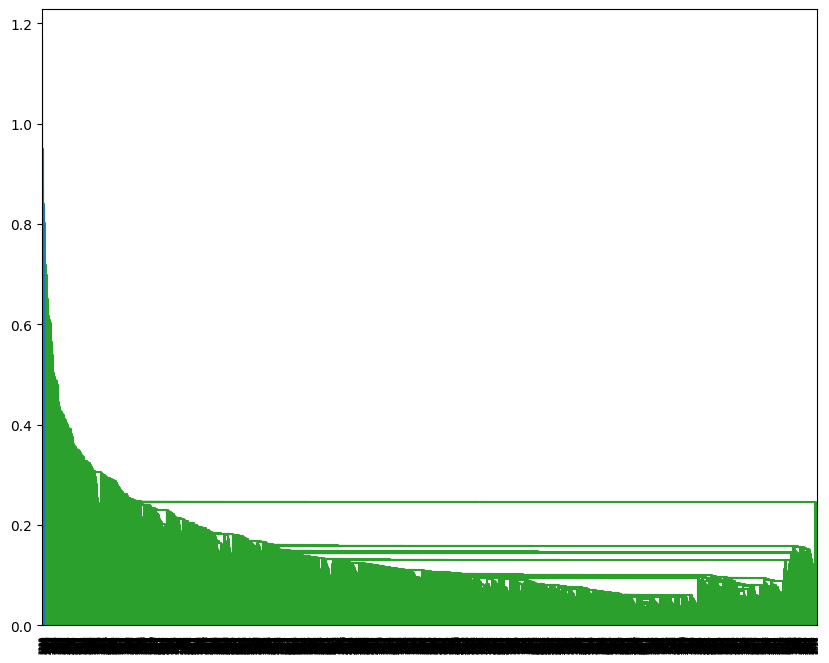

In [61]:
mergings = linkage(dataset_scaled, method="single", metric='euclidean')
dendrogram(mergings)
plt.show()

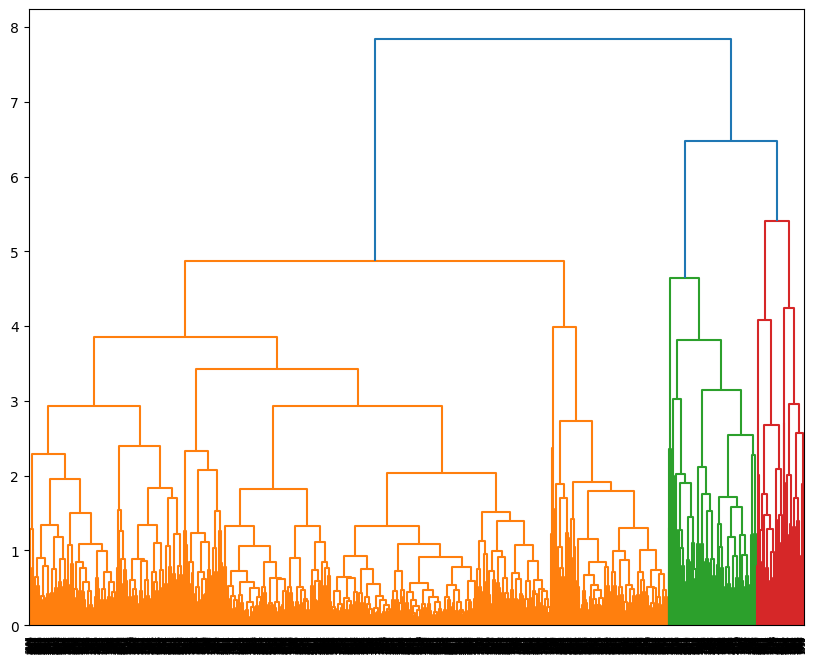

In [62]:
# Complete linkage
mergings = linkage(dataset_scaled, method="complete", metric='euclidean')
dendrogram(mergings)
plt.show()

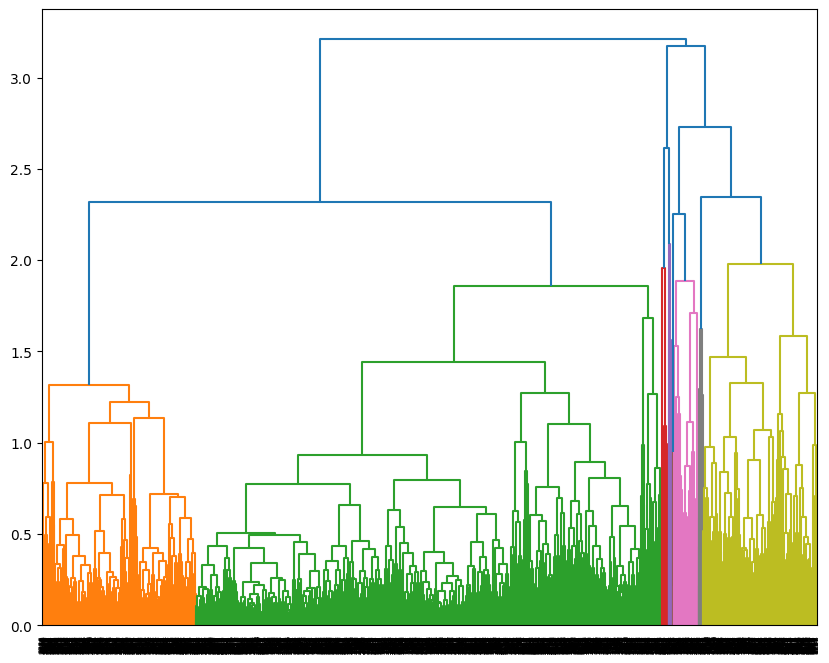

In [63]:
# Average linkage
mergings = linkage(dataset_scaled, method="average", metric='euclidean')
dendrogram(mergings)
plt.show()

In [64]:
# Corte da árvore em 5 clusters (average linkage, definido acima)
cluster_labels = cut_tree(mergings, n_clusters=5).reshape(-1, )
cluster_labels

array([0, 0, 1, ..., 0, 0, 1])

In [65]:
dataset['Cluster_Labels'] = cluster_labels
dataset.head()

,Customer ID,Amount,Frequency,Recency,Cluster_Labels
1,12347.0,1323.32,71,2,0
2,12348.0,222.16,20,73,0
3,12349.0,2646.99,107,42,1
4,12351.0,300.93,21,10,0
5,12352.0,343.80,18,10,0


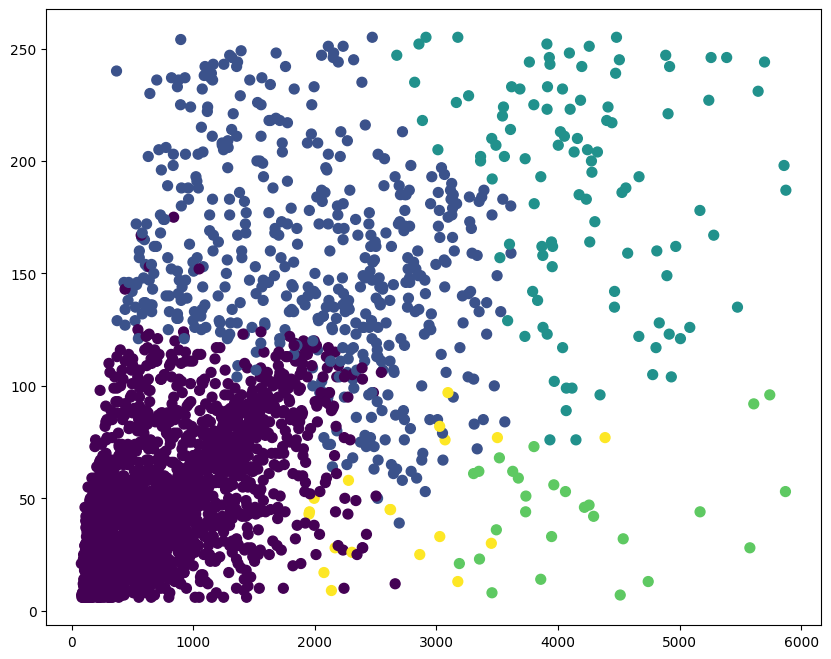

In [67]:
# Os grupos foram calculados com três atributos padronizados, incluindo Recency.
# Esta projeção omite Recency e mostra Amount/Frequency nos valores originais.
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(dataset["Amount"], dataset["Frequency"], c=cluster_labels, s=50, cmap="viridis")
ax.set_xlabel("Amount (valores monetários originais)")
ax.set_ylabel("Frequency (contagem de linhas)")
ax.set_title("Agrupamento hierárquico: projeção em duas dimensões")
fig.tight_layout()
plt.show()